# Exercise 3b - Uniform Cost Search

ICS 3202 Artificial Intelligence

Finding the shortest route for the trailer from Nairobi to Kisumu using the graph from part 1.

## Graph
Distances are in km. Roads go both ways so each one is added in both directions.

In [6]:
roads = [
    ('Nairobi', 'Nakuru', 161),
    ('Nairobi', 'Narok', 145),
    ('Nairobi', 'Thika', 45),
    ('Thika', 'Nyeri', 113),
    ('Nyeri', 'Nyahururu', 104),
    ('Nyahururu', 'Nakuru', 63),
    ('Narok', 'Kilgoris', 176),
    ('Kilgoris', 'Kisii', 56),
    ('Kisii', 'Kisumu', 107),
    ('Nakuru', 'Kericho', 107),
    ('Kericho', 'Kisumu', 84),
]

graph = {}
for a, b, km in roads:
    graph.setdefault(a, []).append((b, km))
    graph.setdefault(b, []).append((a, km))

print(graph)

{'Nairobi': [('Nakuru', 161), ('Narok', 145), ('Thika', 45)], 'Nakuru': [('Nairobi', 161), ('Nyahururu', 63), ('Kericho', 107)], 'Narok': [('Nairobi', 145), ('Kilgoris', 176)], 'Thika': [('Nairobi', 45), ('Nyeri', 113)], 'Nyeri': [('Thika', 113), ('Nyahururu', 104)], 'Nyahururu': [('Nyeri', 104), ('Nakuru', 63)], 'Kilgoris': [('Narok', 176), ('Kisii', 56)], 'Kisii': [('Kilgoris', 56), ('Kisumu', 107)], 'Kisumu': [('Kisii', 107), ('Kericho', 84)], 'Kericho': [('Nakuru', 107), ('Kisumu', 84)]}


## UCS
The queue is a heap so the path with the lowest cost so far is always taken out first.

In [7]:
import heapq

def ucs(graph, start, goal):
    queue = [(0, start, [start])]
    visited = set()

    while queue:
        cost, town, path = heapq.heappop(queue)
        if town in visited:
            continue
        visited.add(town)

        if town == goal:
            return path, cost

        for next_town, km in graph[town]:
            if next_town not in visited:
                heapq.heappush(queue, (cost + km, next_town, path + [next_town]))

    return None, None

## Result

In [8]:
path, cost = ucs(graph, 'Nairobi', 'Kisumu')
print('Path:', ' -> '.join(path))
print('Distance:', cost, 'km')

Path: Nairobi -> Nakuru -> Kericho -> Kisumu
Distance: 352 km


## Group work
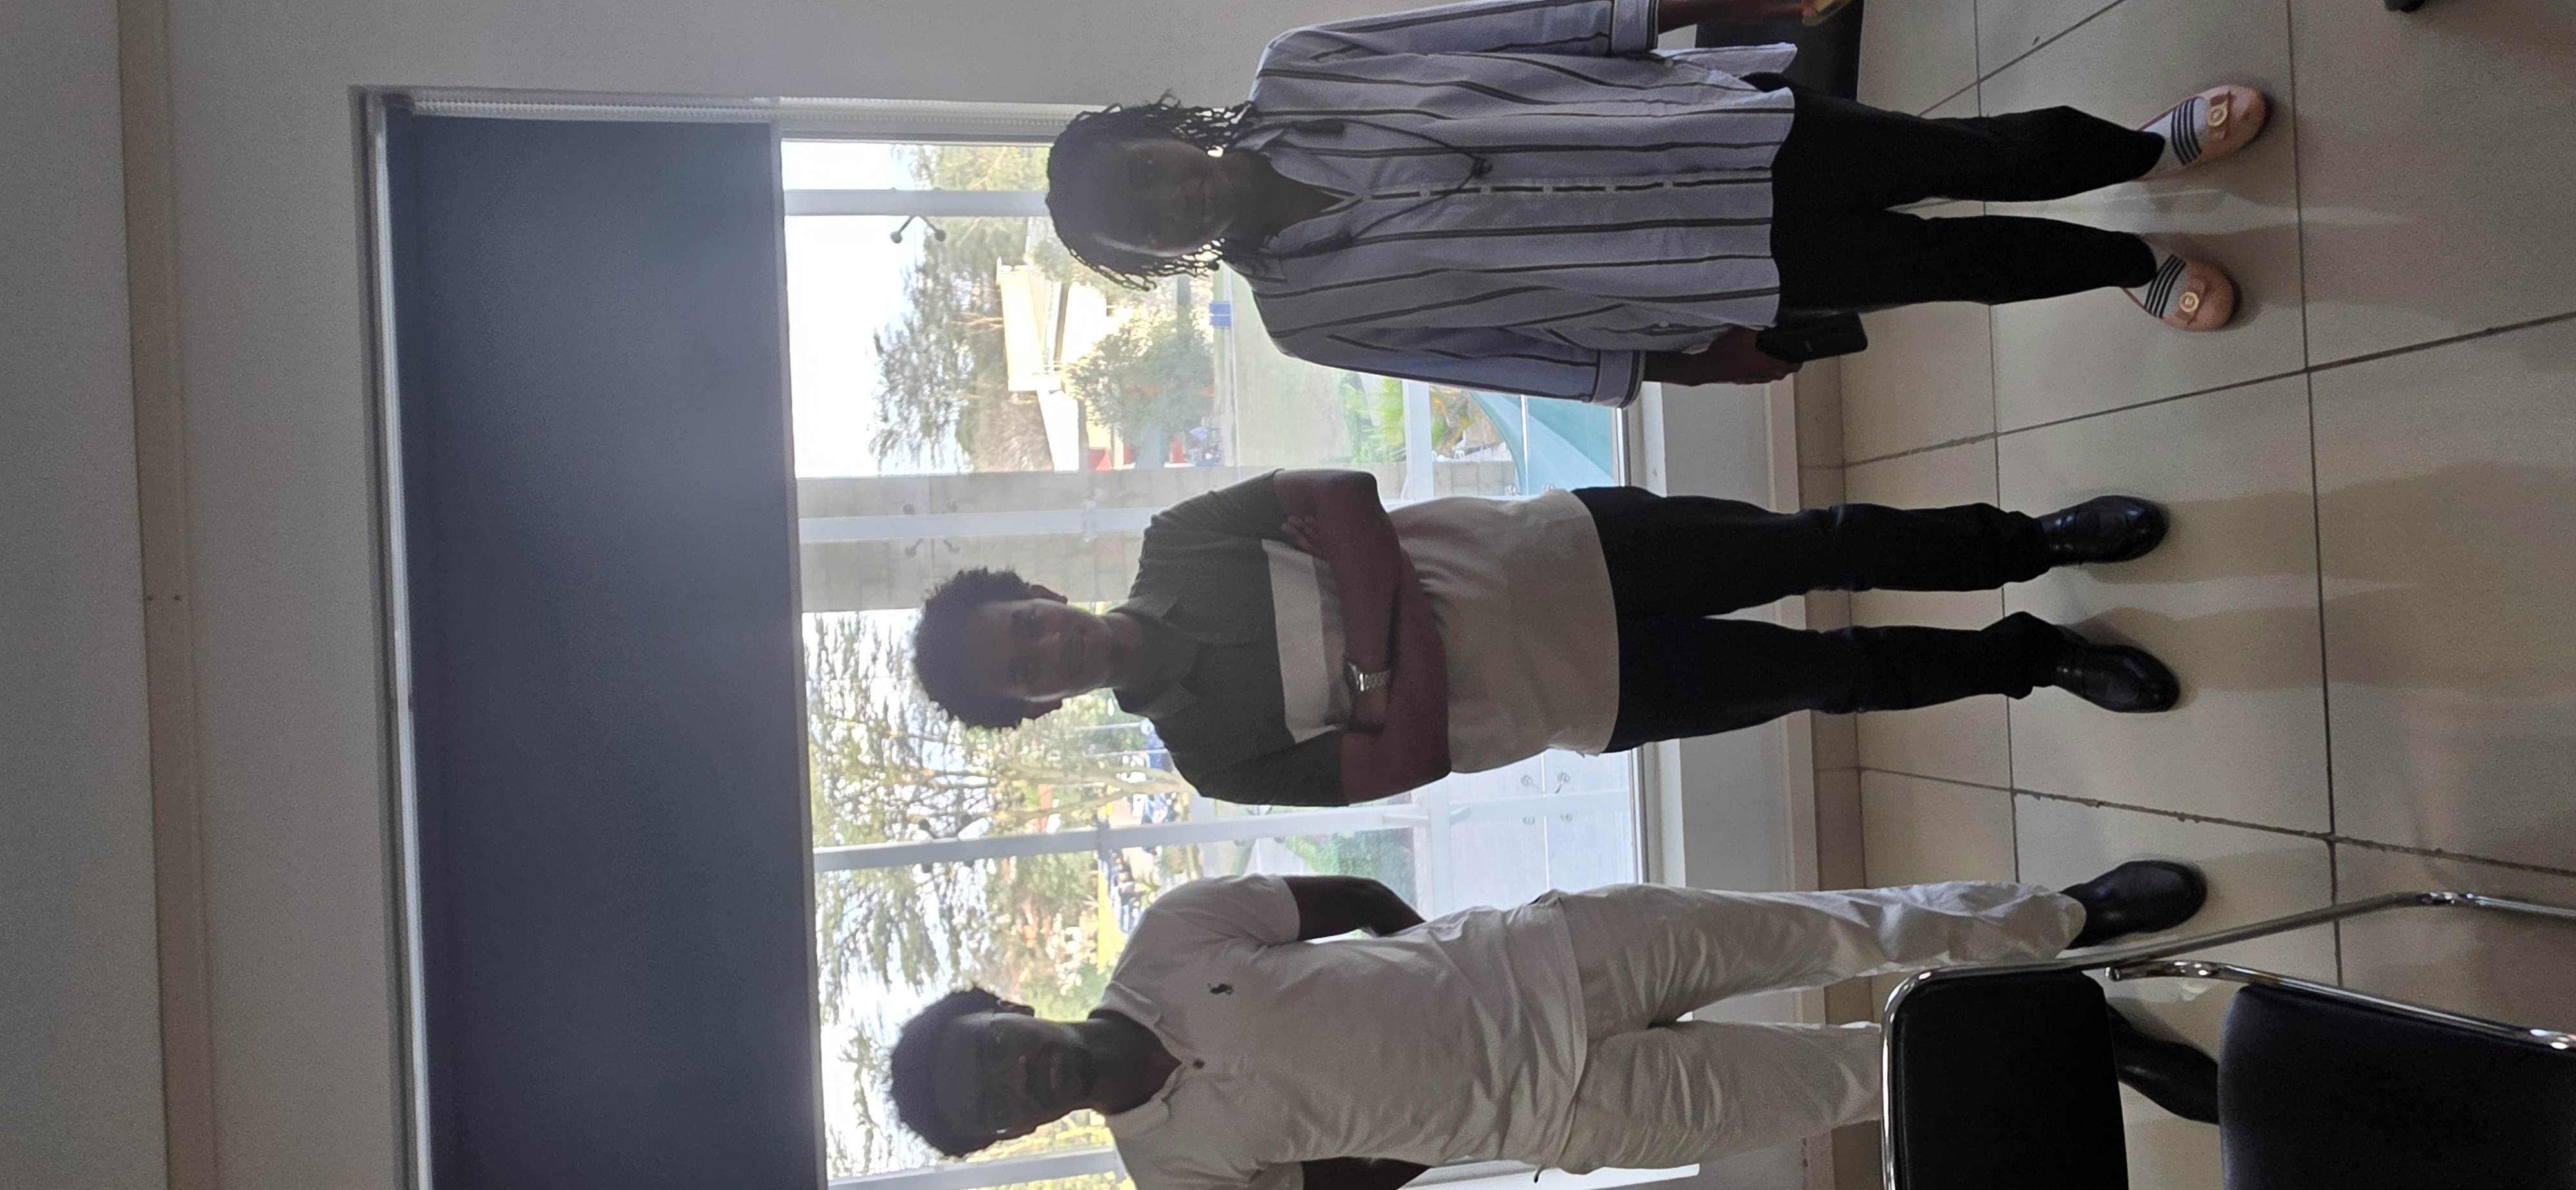